In [46]:
import numpy as np

In [47]:
v = np.array([3,4])

In [48]:
print(v)

[3 4]


In [49]:
print(type(v))

<class 'numpy.ndarray'>


In [50]:
w = np.array([1, 2])

# Vector Addition

In [51]:
print(v + w)

[4 6]


# Scalar multiplication

In [52]:
print(w)

[1 2]


In [53]:
print(v*2)

[6 8]


# dot product

In [54]:
dot = np.dot(v, w)

In [55]:
print(dot)

11


# vector magnitude (length)

In [56]:
length = np.linalg.norm(v)

In [57]:
print(length)

5.0


In [58]:
A = np.array([[1, 2], [3, 4]])

In [59]:
print(A)

[[1 2]
 [3 4]]


In [60]:
print(A.shape)

(2, 2)


# matrix multiplication

In [61]:
B = np.array([[5, 6], [7, 8]])

In [62]:
result = np.matmul(A, B)

In [63]:
print(result)

[[19 22]
 [43 50]]


#### matrix multiplication is just many dot products organized into a grid.

#### When a neural network processes a batch of inputs, it's literally doing inputs @ weights — one matrix multiplication, applying the same dot-product logic to every data point in the batch simultaneously. That's why GPUs are good at ML — they're built to do thousands of these multiplications in parallel.

### identity and transpose matrix

In [64]:
I = np.eye(2)

In [65]:
print(I)

[[1. 0.]
 [0. 1.]]


In [66]:
print(A.T)

[[1 3]
 [2 4]]


##### np.eye(2) gives the identity matrix — [[1,0],[0,1]]. Think of it like the number "1" but for matrices: multiply anything by it and you get the same thing back. It shows up in ML for things like resetting weights or solving systems of equations.
A.T is the transpose — rows become columns. Your [[1,2],[3,4]] became [[1,3],[2,4]]. This is everywhere in ML code — you'll see .T constantly when reshaping data to match what a model expects, or in the math behind backpropagation.
That's a genuinely solid first session: vectors, addition, scalar multiplication, dot product, magnitude, matrices, matrix multiplication, identity matrix, transpose — with actual intuition behind every one, not just syntax memorized.

#### Mean, Variance, and Standard Deviation 

In [67]:
import numpy as np

In [68]:
scores = np.array([70, 80, 90, 85, 75])

In [69]:
print(scores)

[70 80 90 85 75]


In [70]:
mean = np.mean(scores)
variance = np.var(scores)
std = np.std(scores)

In [71]:
print(f"Mean: {mean}")
print(f"Variance: {variance}")
print(f"Std Dev: {std}")

Mean: 80.0
Variance: 50.0
Std Dev: 7.0710678118654755


In [72]:
distances = scores - mean
squared = distances ** 2

In [73]:
print(distances)
print(squared)
print(np.mean(squared))

[-10.   0.  10.   5.  -5.]
[100.   0. 100.  25.  25.]
50.0


Variance = how spread out your data is from the mean.
Small variance → scores are clustered close to 80.
Large variance → scores are scattered far from 80.
The reason we square the distances is so that negative distances (scores below 80) don't cancel out positive ones (scores above 80). We want all distances to count positively.
Std Dev is just variance back in the original units — since we squared the distances, the units got squared too. Taking the square root brings it back. So std dev of 7.07 means: on average, scores are about 7 points away from the mean.
That's it. Variance and std dev measure the same thing — spread — just in different scales.
Why this matters for ML: before feeding data into a model, features with huge variance (like salary: 50,000–200,000) will dominate features with small variance (like age: 20–60). So you normalize everything — subtract mean, divide by std — to put all features on equal footing.

variance = Σ(x - mean)² / n

std_dev = √variance

The relationship:
They measure the same thing — spread — but in different units:

Variance is in squared units (exam points²) — hard to interpret intuitively
Std dev is in original units (exam points) — easy to interpret: "scores are typically 7 points from the mean"

So you calculate variance first, then take the square root to get std dev back into units humans can understand.

In [74]:
normalized = (scores - mean) / std

In [75]:
print(f"Original: {scores}")
print(f"Normalized: {normalized}")
print(f"New mean: {np.mean(normalized):.4f}")
print(f"New std: {np.std(normalized):.4f}")

Original: [70 80 90 85 75]
Normalized: [-1.41421356  0.          1.41421356  0.70710678 -0.70710678]
New mean: 0.0000
New std: 1.0000


This is called standardization — after this transformation, every feature has mean=0 and std=1, regardless of original scale. A salary feature (50,000–200,000) and an age feature (20–60) both end up on the same scale — so neither dominates the model unfairly.

Quick summary:

Mean — center of data, best single guess

Variance — average squared distance from mean

Std Dev — square root of variance, same units as data

Standardization — subtract mean, divide by std → mean=0, std=1, puts all features on equal footing

#### Distributions — specifically the normal distribution, which shows up everywhere in ML (error distributions, weight initialization, noise modeling).

In [76]:
import matplotlib.pyplot as plt

In [77]:
samples = np.random.randn(1000)

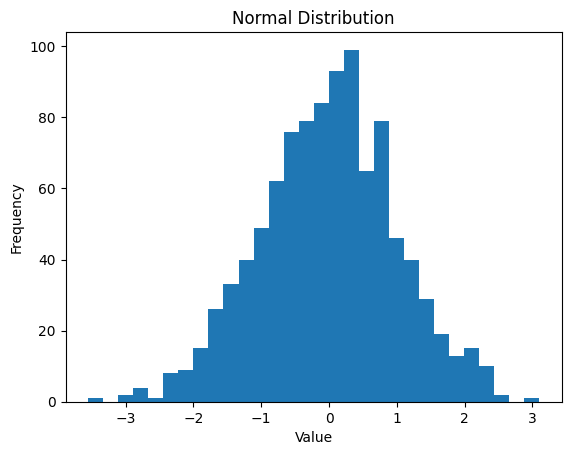

In [78]:
plt.hist(samples, bins=30)
plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

The shape is actually a bell curve (normal distribution). With 1000 samples it's not perfectly smooth, but the peak in the middle and tapering on both sides is exactly right.

####
np.random.randn(1000) — generates 1000 random numbers from a standard normal distribution (mean=0, std=1). You already know what that means now.
plt.hist(samples, bins=30) — draws a histogram:

samples — the data to plot
bins=30 — divides the x-axis into 30 buckets, counts how many values fall in each bucket, draws a bar for each. More bins = more detail but noisier. Fewer bins = smoother but less detail.

plt.title(...) — adds a title to the chart.
plt.xlabel(...) / plt.ylabel(...) — labels the x and y axes.
plt.show() — actually renders and displays the plot. Without this, nothing shows up.
Why normal distribution matters for ML:

Errors in predictions tend to follow it.
Neural network weights are often initialized from it.
Many ML algorithms assume your data is roughly normally distributed

In [79]:
from scipy import stats

In [80]:
x = np.linspace(-4, 4, 100)
y = stats.norm.pdf(x, 0, 1)

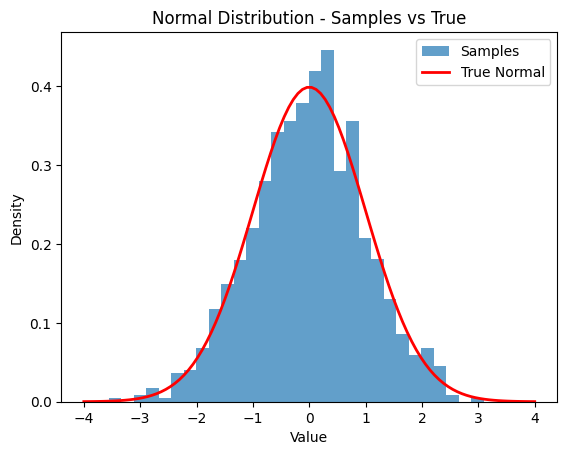

In [81]:
plt.hist(samples, bins=30, density=True, alpha=0.7, label="Samples")
plt.plot(x, y, color='red', linewidth=2, label="True Normal")
plt.title("Normal Distribution - Samples vs True")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

explaining the new parameters:

density=True — scales the histogram so area = 1 (converts frequency to probability density), so it's comparable to the theoretical curve
alpha=0.7 — makes the histogram slightly transparent (0=invisible, 1=solid) so you can see the red line behind it
plt.plot(x, y) — draws the smooth theoretical bell curve in red
plt.legend() — shows the label key for both lines

Great — that red line is the theoretical perfect bell curve, and your histogram of 1000 random samples is hugging it closely. That's the normal distribution in action.
Notice:

Peak at 0 — most values cluster around the mean
Tails taper off symmetrically — extreme values are rare but possible
Your samples approximate the true curve well — 1000 points is enough to see the shape clearly

One important thing to internalize: in ML, you want your model's errors to look like this. If you plot actual - predicted for a well-trained model and it looks like this bell curve centered at 0, your model is doing well — errors are random, small, and unbiased. If the distribution is skewed or has a weird shape, something is wrong with the model.

np.linspace — generates evenly spaced numbers between two points. You'll see it constantly for plotting.
stats.norm.pdf — gives the theoretical probability at each point on a normal curve
density=True — scales histogram to probability

**What is a normal distribution?**

It's a pattern that data naturally falls into when many independent random factors influence the outcome.

Classic example: human height. Your height is influenced by hundreds of genes, nutrition, environment — all independent factors adding up. The result? Most people cluster around the average (say 5'9"), fewer people are very tall or very short, and the further you go from the average in either direction, the rarer it gets.

That pattern — **peak in the middle, tapering symmetrically on both sides** — is the normal distribution. Also called the bell curve.

Mathematically it's defined by just two numbers:
- **Mean (μ)** — where the peak is, the center
- **Std Dev (σ)** — how wide or narrow the bell is. Small std dev = tall narrow bell (data clustered tightly). Large std dev = short wide bell (data spread out).

**The 68-95-99.7 rule** — worth knowing:
- 68% of data falls within 1 std dev of the mean
- 95% within 2 std devs
- 99.7% within 3 std devs

So for exam scores with mean=80, std=7: 95% of students scored between 66 and 94.

**Why it matters for ML:**

First, **errors follow it.** When your model makes prediction errors, they tend to be normally distributed — small errors are common, large errors are rare. This assumption is baked into linear regression mathematically.

Second, **weight initialization.** When you start training a neural network, you initialize weights randomly from a normal distribution — not too big, not too small, centered at zero.

Third, **the Central Limit Theorem** — one of the most powerful ideas in statistics. It says: take any data, compute averages of random samples, and those averages will be normally distributed regardless of what the original data looked like. This is why normal distribution assumptions hold even when your raw data isn't perfectly normal.

Fourth, **anomaly detection.** If your data is normally distributed, anything beyond 3 std devs from the mean is extremely rare (0.3% chance). So you flag it as an anomaly — useful in fraud detection, which is directly relevant to your finance background.

Short version: **normal distribution is nature's default pattern, and ML is built on top of that assumption in dozens of ways.**

Simple arithmetic using the 68-95-99.7 rule.

95% of data falls within **2 std devs** of the mean in either direction.

So:
- Mean = 80
- Std dev = 7

**Lower bound** = mean − (2 × std dev) = 80 − 14 = **66**

**Upper bound** = mean + (2 × std dev) = 80 + 14 = **94**

So 95% of students scored between 66 and 94. Only 5% scored below 66 or above 94 — those are the outliers on either tail of the bell curve.

You can apply this to any normal distribution:

| Range | Coverage |
|-------|----------|
| mean ± 1 std dev | 68% of data |
| mean ± 2 std devs | 95% of data |
| mean ± 3 std devs | 99.7% of data |

So for your scores with mean=80, std=7:
- 68% scored between **73 and 87**
- 95% scored between **66 and 94**
- 99.7% scored between **59 and 101**

This is one of those rules worth memorizing — you'll use it instinctively when looking at data to quickly spot outliers and understand spread.

In [82]:
mean = np.mean(samples)
std = np.std(samples)

In [83]:
within_1 = np.sum((samples >= mean - std) & (samples <= mean + std)) / len(samples) * 100
within_2 = np.sum((samples >= mean - 2*std) & (samples <= mean + 2*std)) / len(samples) * 100
within_3 = np.sum((samples >= mean - 3*std) & (samples <= mean + 3*std)) / len(samples) * 100


In [84]:
print(f"Within 1 std dev: {within_1:.1f}%")
print(f"Within 2 std devs: {within_2:.1f}%")
print(f"Within 3 std devs: {within_3:.1f}%")

Within 1 std dev: 69.2%
Within 2 std devs: 94.7%
Within 3 std devs: 99.7%


Almost exactly 68, 95, 99.7 — tiny differences because we only have 1000 samples, not infinite. With 10,000 samples it'd be even closer.
The rule holds. You just verified it empirically in code, not just took it on faith. That's the right way to learn this stuff.
Quick explanation of the code logic since it had some new syntax:
(samples >= mean - std) & (samples <= mean + std) — this creates a True/False array for every sample. True if it falls within 1 std dev, False if not.
np.sum(...) — counts the Trues (since True=1, False=0).
Divide by len(samples) and multiply by 100 — converts count to percentage.
That pattern — boolean masking — is something you'll use constantly in pandas and numpy when filtering data.

### Probability Basics

probability basics — the foundation of how ML models express uncertainty and make decisions.
Quick intuition first: probability is just a number between 0 and 1 expressing how likely something is. 0 = impossible, 1 = certain, 0.5 = coin flip.
In ML this shows up everywhere — a classification model doesn't just say "this email is spam," it says "this email is spam with 94% probability." Understanding probability is what lets you interpret and trust model outputs.

In [85]:
import numpy as np

In [86]:
# simulate 10000 coin flips
flips = np.random.choice(['H', 'T'], size=10000)

In [87]:
heads = np.sum(flips == 'H')
tails = np.sum(flips == 'T')

In [88]:
print(f"Heads: {heads}, probability: {heads/10000:.4f}")
print(f"Tails: {tails}, probability: {tails/10000:.4f}")

Heads: 4998, probability: 0.4998
Tails: 5002, probability: 0.5002


Perfect — almost exactly 0.5 each. The tiny difference is just random noise from finite samples, same as the 68-95-99.7 rule earlier.
This demonstrates the law of large numbers — the more samples you take, the closer your observed probability gets to the true probability. With 100 flips you might get 60 heads. With 10,000 you'll always be close to 5000.
Why this matters for ML: your training data is a sample of reality. The larger and more representative it is, the closer your model's learned probabilities are to the true underlying distribution. Small datasets = noisy, unreliable probabilities. Large datasets = stable, trustworthy ones.

Now let's move to something more ML-relevant — **conditional probability**. This is the idea behind Naive Bayes classifiers and Bayesian reasoning in general.
Concept first: P(A|B) means "probability of A given B has already happened."
Real example:

P(spam) = 0.3 — 30% of all emails are spam
P(spam | contains "free money") = 0.95 — if email contains "free money", 95% chance it's spam

The condition changes the probability dramatically. That's conditional probability.

In [89]:
# simulate 10000 emails
np.random.seed(42)
n = 10000

In [90]:
spam = np.random.choice([0, 1], size=n, p=[0.7, 0.3])

In [92]:
free_money = np.where(spam == 1, 
                       np.random.choice([0,1], size=n, p=[0.1, 0.9]),
                       np.random.choice([0,1], size=n, p=[0.99, 0.01]))

In [93]:
print(f"Total spam: {np.sum(spam)}")
print(f"Total with 'free money': {np.sum(free_money)}")

Total spam: 2887
Total with 'free money': 2680


We simulated 10,000 emails with two properties — whether it's spam, and whether it contains "free money."
np.random.choice([0, 1], size=n, p=[0.7, 0.3]) — for each of 10,000 emails, randomly assign spam=1 with 30% probability, spam=0 with 70%. Result: ~2887 spam emails out of 10,000. Close to 30% ✓
np.where(spam == 1, ..., ...) — this says: if the email is spam, generate "free money" with 90% probability. If it's not spam, generate "free money" with only 1% probability.
So:

~2887 spam emails × 90% = ~2598 spam emails with "free money"
~7113 non-spam emails × 1% = ~71 non-spam emails with "free money"
Total with "free money" ≈ 2669 — close to your 2680 ✓

In [94]:
# emails that contain "free money"
has_free_money = free_money == 1

In [95]:
# of those, how many are spam?
p_spam_given_free_money = np.sum((spam == 1) & has_free_money) / np.sum(has_free_money)


In [96]:
print(f"P(spam | 'free money'): {p_spam_given_free_money:.4f}")

P(spam | 'free money'): 0.9683


"Free money" appears in 90% of spam emails but only 1% of non-spam. So when you see "free money", it's a very strong signal that the email is spam. The probability should be closer to 95%+.
The 30% was the baseline probability of spam before you saw any evidence. Seeing "free money" updates that probability dramatically upward. That's the whole point of conditional probability — new evidence changes your belief.

96.8% — exactly as expected. Strong signal word → high conditional probability of spam. That's literally how a Naive Bayes spam filter works under the hood.

Remember the concepts:

Conditional probability P(A|B) — probability of A given B
New evidence updates probability (seeing "free money" changed 30% → 97%)
Law of large numbers — more data = more reliable probabilities

Remember the patterns:

np.where(condition, value_if_true, value_if_false) — you'll use this constantly for data manipulation
Boolean masking with & — filtering data by multiple conditions
np.sum(condition) / total — computing probabilities from data

**Bayes Theorem**

Bayes theorem is just conditional probability written as a formula. Here it is:
P(A|B) = P(B|A) × P(A) / P(B)
In spam terms:

P(A|B) = P(spam | "free money") — what we want to find
P(B|A) = P("free money" | spam) — how often spam contains "free money" (90%, we set this)
P(A) = P(spam) — baseline spam probability (30%, we set this)
P(B) = P("free money") — how often any email contains "free money"

Each term has a name:

P(A|B) = posterior — updated belief after seeing evidence
P(A) = prior — belief before seeing any evidence
P(B|A) = likelihood — how likely the evidence is if A is true
P(B) = evidence — normalizing factor

In [97]:
p_spam = np.mean(spam)
p_free_money_given_spam = np.mean(free_money[spam == 1])
p_free_money = np.mean(free_money)

In [98]:
p_spam_given_free_money_bayes = (p_free_money_given_spam * p_spam) / p_free_money

In [99]:
print(f"P(spam): {p_spam:.4f}")
print(f"P('free money' | spam): {p_free_money_given_spam:.4f}")
print(f"P('free money'): {p_free_money:.4f}")
print(f"P(spam | 'free money') via Bayes: {p_spam_given_free_money_bayes:.4f}")

P(spam): 0.2887
P('free money' | spam): 0.8989
P('free money'): 0.2680
P(spam | 'free money') via Bayes: 0.9683


This is a big moment conceptually. You just verified that:
Prior belief (30% spam) + Evidence ("free money") = Updated belief (97% spam)
That's Bayesian thinking in one sentence. And it's not just for spam filters — this same logic appears in:

Medical diagnosis — P(disease | test result)
Fraud detection — P(fraud | transaction pattern)
Recommendation systems — P(user likes X | user liked Y)
Any ML model that outputs probabilities — they're all doing some version of this



The reason Bayes theorem is so powerful is it gives you a principled way to update beliefs with new evidence. Every time your model sees a new feature, it's updating its probability estimate — Bayes theorem is the mathematical foundation of that update.
Quick summary of what you've covered today:

Probability basics and law of large numbers
Conditional probability P(A|B)
Bayes theorem — prior, likelihood, evidence, posterior
Verified everything empirically in code

Probability distributions in ML context — specifically the difference between two types you'll encounter constantly:

**Discrete distributions** — countable outcomes (spam/not spam, cat/dog/bird)
**Continuous distributions** — infinite possible values (house price, temperature, salary)

You already know the normal distribution (continuous). Let's quickly cover one discrete one that's everywhere in ML — the **Bernoulli distribution**. It's just a single coin flip: one event, two outcomes, one probability p.

In [100]:
# Bernoulli - single trial, probability p of success
p = 0.3  # probability of spam

In [101]:
samples_bernoulli = np.random.binomial(n=1, p=p, size=10000)

In [102]:
print(f"P(spam=1): {np.mean(samples_bernoulli):.4f}")
print(f"P(spam=0): {1 - np.mean(samples_bernoulli):.4f}")

P(spam=1): 0.3037
P(spam=0): 0.6963


p here is the probability of getting a 1 (success) in a single trial.
So p=0.3 means every email has a 30% chance of being spam. Same as what we set earlier.
np.random.binomial(n=1, p=0.3, size=10000) breaks down as:

n=1 — one trial per experiment (just one coin flip, not multiple)
p=0.3 — probability of getting 1 (spam) on each trial
size=10000 — repeat this 10,000 times

When n=1, binomial is exactly the same as Bernoulli — just one trial with two possible outcomes: 1 (spam, 30% chance) or 0 (not spam, 70% chance).
Think of it like this: you're flipping a biased coin 10,000 times where heads (spam) comes up 30% of the time.

0.30 and 0.70, tiny deviation due to finite samples as always.
That's the Bernoulli distribution — simplest possible probability distribution, but it's the building block of binary classification in ML. Every time a model predicts "spam or not spam", "fraud or not fraud", "click or not click" — it's outputting a Bernoulli probability.

### Note:

**Why distributions matter in ML**, tied together in one concept:
When you choose a loss function for your model, you're implicitly assuming a probability distribution for your output:

Binary classification (spam/not spam) → Bernoulli distribution → binary cross-entropy loss

Multi-class classification (cat/dog/bird) → Categorical distribution → categorical cross-entropy loss

Regression (predicting house price) → Normal distribution → mean squared error loss

When you start building models in a few weeks and choose a loss function, come back to this. The loss function choice is just you telling the model which probability distribution you think your data follows.

**Simple definition: a loss function measures how wrong your model's prediction is.**

During training, your model makes a prediction, compares it to the true answer, and the loss function gives a single number — **how bad was that prediction?** The model then adjusts its weights to make that number smaller. Repeat millions of times — that's training.

Concrete example:
Say you're predicting house prices. Model predicts $300,000, true price is $350,000. The error is $50,000.
Mean Squared Error (MSE) — most common regression loss:
loss = (predicted - actual)² = (300,000 - 350,000)² = 2,500,000,000
You square it so:

Negative errors don't cancel positive ones

Large errors are punished more than small ones (squaring amplifies big mistakes)

For classification — say spam detection. Model outputs probability 0.2 (20% spam), true label is 1 (it is spam). That's a bad prediction. Cross-entropy loss measures how far your probability was from the truth — the further away, the higher the loss.

The big picture:
Model predicts → Loss function scores the error → 
Model adjusts weights → Repeat until loss is minimized



The entire training process is just minimizing the loss function. That's it. Different problems need different ways of measuring error — that's why different loss functions exist.